> **中文阅读版**：本文件是 `11_library_landscape.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 同一个预测，六种写法

**Docker image**：`ml4t-gpu`

本章的每个 notebook 都是直接基于 PyTorch 编写的：一个模型类、一个训练循环、一个评估代码块。这是学习单一一一种架构的正确方式，但要尝试五种架构就很糟糕。本 notebook 用多个库编写同一个单变量预测，并比较*使用体验*——需要多少行代码、需要安装什么、接口带来了哪些约束。

**sktime** 是最值得理解的一个，因为它不是一个模型库。它是一个接口——`fit`、`predict`、`update`——将工作委托给 NeuralForecast、PyTorch Forecasting、HuggingFace 以及经典方法，因此把 LSTM 换成 Chronos 或 ARIMA 只是改一下构造函数，而不是重写。**Darts** 走的是另一条路：它有自己的 `TimeSeries` 容器和自己的模型实现。

**这张表衡量的是工作量，而不是准确率。** 各行并不共享相同的目标尺度或测试集，因此误差列不能跨行比较——这一点在表格出现处有说明，并在表格自身的列中标注。特意加入一个最后值基线，正是为了让唯一一个*真正同类*的比较出现在页面上。

**学习目标**：
- 分别针对原始框架和封装器编写同一个预测，并数一数封装器究竟省下了什么。
- 读懂一张对比表，辨别哪些列可以跨行比较、哪些不能。
- 说明当目标是价格水平而非收益率时，秩相关意味着什么。
- 判断在什么情况下，接口带来的约束值得它省去的样板代码。

**书中参考**：第 13 章，13.7 节（A practical framework）

**前置条件**：通过规范化的 `load_etfs()` 加载器获取 ETF 价格数据

In [1]:
"""Library Landscape - compare raw PyTorch vs sktime-wrapped forecasting implementations."""

import logging
import tempfile
import time
import warnings
from datetime import datetime

# pytorch_lightning emits this at import time, which `from darts...` below triggers, so
# the filter has to be installed before the import rather than alongside the others.
warnings.filterwarnings(
    "ignore",
    message=r".*LeafSpec.*is deprecated",
    module=r".*pytorch_lightning.*",
)

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import polars as pl
import torch
import torch.nn as nn
from darts import TimeSeries
from darts.models import RNNModel
from ml4t.diagnostic.metrics import pooled_ic
from sktime.forecasting.chronos import ChronosForecaster
from sktime.forecasting.patch_tst import PatchTSTForecaster

from data import load_etfs
from utils.reproducibility import set_global_seeds
from utils.style import (  # COLORS activates the ml4t Plotly template on import
    COLORS,
    show_plotly_with_alt,
)

下面的三个库会向标准错误输出进度横幅——它们选中的加速器、安装日志集成（logging integration）的建议、经 sktime 的 Chronos 封装器触达的 `transformers` 内部弃用提示。这些都没有报告问题，也都不属于本 notebook 的输出，因此通过各自 logger 按名称静音，而不是一概过滤。这些库以警告形式抛出的任何内容仍会进入渲染。

In [2]:
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
logging.getLogger("darts").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)

In [3]:
SEED = 42
LOOKBACK = 60
HORIZON = 5
HIDDEN_SIZE = 64
EPOCHS = 30
BATCH_SIZE = 32
START_DATE = "2015-01-01"

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

set_global_seeds(SEED)

Device: cuda


## 数据：SPY 收盘价

我们使用单一的单变量序列（SPY 每日收盘价），使每个库看到完全相同的输入。我们准备两种表示：用于原始 PyTorch 的 NumPy 序列，以及用于 sktime/Darts 的带交易日索引的 pandas Series。

In [5]:
etf_df = load_etfs()
start_dt = datetime.fromisoformat(START_DATE)

spy = (
    etf_df.filter((pl.col("symbol") == "SPY") & (pl.col("timestamp") >= start_dt))
    .sort("timestamp")
    .select(["timestamp", "close"])
)

prices = spy["close"].to_numpy().astype(np.float32)
n_seq = len(prices) - LOOKBACK - HORIZON + 1
split_idx = int(n_seq * 0.8)
train_price_end = split_idx + LOOKBACK + HORIZON
price_mean = prices[:train_price_end].mean()
price_std = prices[:train_price_end].std()
prices_norm = (prices - price_mean) / price_std

print(f"SPY: {len(prices):,} daily observations")

SPY: 2,766 daily observations


上面两步的顺序很重要。训练/测试边界*先*在序列空间中固定下来，然后归一化统计量仅用截至 `train_price_end` 的价格计算——这是任何训练序列所能触及的最后一个价格索引，即其输入窗口加上预测期。若使用整条序列的均值和标准差进行归一化，就会把测试期的价格水平混入训练输入，这是一种在任何划分中都不留痕迹的泄漏（leak）。

### PyTorch 序列（已归一化）

In [6]:
def create_sequences(data, lookback, horizon):
    """Create (input, target) pairs for univariate forecasting."""
    X, y = [], []
    for i in range(len(data) - lookback - horizon + 1):
        X.append(data[i : i + lookback])
        y.append(data[i + lookback : i + lookback + horizon].mean())
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


X, y = create_sequences(prices_norm, LOOKBACK, HORIZON)
# split_idx was fixed above (in price space) so the normalization stays train-only
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

X_train_t = torch.FloatTensor(X_train).unsqueeze(-1).to(DEVICE)
y_train_t = torch.FloatTensor(y_train).unsqueeze(-1).to(DEVICE)
X_test_t = torch.FloatTensor(X_test).unsqueeze(-1).to(DEVICE)

print(f"Sequences: train={len(X_train):,}, test={len(X_test):,}")

Sequences: train=2,161, test=541


### sktime / Darts 序列（带 DatetimeIndex 的价格）

In [7]:
spy_pd = spy.to_pandas()
spy_series = spy_pd.set_index("timestamp")["close"]
spy_series = spy_series.sort_index()
spy_series.index = pd.DatetimeIndex(spy_series.index)

# Reindex to business-day frequency, forward-filling gaps (holidays etc.)
# Libraries like sktime/NeuralForecast and Darts require a regular frequency.
bday_idx = pd.bdate_range(start=spy_series.index.min(), end=spy_series.index.max(), freq="B")
spy_series = spy_series.reindex(bday_idx).ffill().dropna()
spy_series.index.freq = "B"

sk_split = int(len(spy_series) * 0.8)
y_train_sk = spy_series.iloc[:sk_split]
y_test_sk = spy_series.iloc[sk_split : sk_split + HORIZON]
fh_sk = list(range(1, HORIZON + 1))

### 评估辅助函数

**这里的 IC 不是本章其他地方的那个 IC。** Notebook 04 到 10 计算的是*横截面*秩相关：在每个日期上，各基金的预测排名是否与实现排名一致？这里只有一个序列，因此没有横截面，而这个辅助函数计算的是预测值与实际值跨时间的秩相关。

在价格水平上，任何跟踪该水平的对象都会让这个数字接近 1，包括仅仅重复最后一次观测的预测——下面的基线就说明了这一点。把 `ic` 列理解为检查模型没有输出胡言乱语的手段，其余一概看 MSE。

In [8]:
def evaluate(y_true, y_pred):
    """Compute MSE and Spearman IC."""
    mse = float(np.mean((y_true - y_pred) ** 2))
    ic = pooled_ic(y_pred, y_true) if len(y_true) > 5 else float("nan")
    return {"mse": round(mse, 6), "ic": round(ic, 4) if np.isfinite(ic) else None}


results = []  # Collector for final comparison

### 需要超越的预测

在任何库之前：把接下来 `HORIZON` 天的均值预测为最后观测到的价格。它只花一行代码，是下面每个模型都必须改进的基准，而在价格水平上它很难被超越——这正是它应该出现在表中的原因。

IC 列需要同样的提醒。在呈趋势的价格水平上，任何跟踪该水平的预测都会与结果几乎完全相关，因此接近 1 的秩相关是关于序列的陈述，而不是关于模型的陈述。基线行正是让这一点变得可见的存在。

In [9]:
preds_naive = X_test[:, -1]
m_naive = evaluate(y_test, preds_naive)
results.append(
    {
        "Model": "Last value",
        "Library": "None",
        "Lines": "~1",
        "Fit + Predict (s)": 0.0,
        **m_naive,
        "Trainable": False,
        "Target Scale": "normalized",
        "Evaluation Points": len(y_test),
    }
)
print(f"Last-value baseline: MSE={m_naive['mse']}, IC={m_naive['ic']}")

Last-value baseline: MSE=0.007613, IC=0.9905


## 第 1 部分：原始 PyTorch LSTM

“完全控制”的基线：模型定义、训练循环和评估需要大约 50 行样板代码。

In [10]:
class LSTMForecaster(nn.Module):
    """Minimal LSTM for univariate forecasting."""

    def __init__(self, hidden_size, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

In [11]:
model = LSTMForecaster(HIDDEN_SIZE).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

start = time.time()
for epoch in range(EPOCHS):
    model.train()
    indices = torch.randperm(len(X_train_t))
    epoch_loss, n_batches = 0.0, 0
    for i in range(0, len(X_train_t), BATCH_SIZE):
        batch_idx = indices[i : i + BATCH_SIZE]
        loss = criterion(model(X_train_t[batch_idx]), y_train_t[batch_idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    if (epoch + 1) % 10 == 0:
        print(f"  Epoch {epoch + 1}/{EPOCHS}: loss={epoch_loss / n_batches:.6f}")
model.eval()
with torch.no_grad():
    preds_pt = model(X_test_t).cpu().numpy().flatten()
pytorch_time = time.time() - start

m = evaluate(y_test, preds_pt)
results.append(
    {
        "Model": "LSTM",
        "Library": "Raw PyTorch",
        "Lines": "~50",
        "Fit + Predict (s)": round(pytorch_time, 1),
        **m,
        "Trainable": True,
        "Target Scale": "normalized",
        "Evaluation Points": len(y_test),
    }
)
print(f"Raw PyTorch LSTM: {pytorch_time:.1f}s, MSE={m['mse']}, IC={m['ic']}")
print(
    f"  against the last-value baseline: MSE={m_naive['mse']}, IC={m_naive['ic']} "
    f"on the same {len(y_test)} points"
)

  Epoch 10/30: loss=0.005351


  Epoch 20/30: loss=0.004241


  Epoch 30/30: loss=0.003760
Raw PyTorch LSTM: 9.8s, MSE=0.287427, IC=0.9893
  against the last-value baseline: MSE=0.007613, IC=0.9905 on the same 541 points


原始 PyTorch LSTM 需要定义模型类、训练循环和评估——大约 50 行。对架构和训练动态拥有完全控制，代价就是这些样板代码。

在把本 notebook 的任何内容当作结果来看之前，先比较上面打印的两行。两者处于同一尺度、同样的测试点，这是这里唯一这样的比较，而基线完全不需要训练。

## 第 2 部分：sktime + NeuralForecast LSTM

sktime 封装了 NeuralForecast 的 LSTM：三行代码即可替代 50 行的训练循环。底层循环架构是等价的。

**依赖说明**：sktime 的神经预测器需要 `neuralforecast`，而后者依赖 `ray`，并且 ray 的 Python 3.14 wheel 仍待发布（[ray-project/ray#56434](https://github.com/ray-project/ray/issues/56434)）。本节描述调用方式，而非实际运行。另请注意，近期 sktime 版本已将封装器的 `hidden_size` 参数重命名为 `encoder_hidden_size`。

当可以发起调用时，其形式为
`NeuralForecastLSTM(freq=..., input_size=..., max_steps=..., encoder_hidden_size=...)`
随后调用 `fit` 和 `predict`——第 1 部分的整个模型类和训练循环被一个构造函数取代。这正是使用封装器的理由，而当前环境也正是不应依赖封装器的理由：上面的代码在这里根本无法运行。

## 第 3 部分：sktime + PyTorch Forecasting N-BEATS

通过 sktime 的 PyTorch Forecasting 封装器使用 N-BEATS（第 13.2 节）。同样的
`fit()`/`predict()` API，底层架构不同。

**依赖说明**：sktime 的 PyTorch Forecasting 封装器需要 `pytorch-forecasting`，而上一次尝试还遇到了围绕 `max_prediction_length` 和 `max_encoder_length` 的封装器 API 不匹配。本节描述调用方式，而非实际运行。

调用形式会是 `PytorchForecastingNBeats(max_prediction_length=...,
max_encoder_length=..., max_epochs=..., trainer_kwargs=...)`，然后与这里的其他所有预测器一样使用相同的 `fit`
和 `predict`——这正是该接口的意义所在：将 LSTM 替换为 `02_nbeats_interpretable` 中的 N-BEATS，只需改一个 import 和一个构造函数，数据管道完全不变。

它也是本 notebook 连续第二个无法执行的封装器，这一点是关于封装器的信息，而非题外话。

## 第 4 部分：sktime PatchTST

通过 sktime 的 HuggingFace 集成使用 PatchTST（第 13.5 节）。支持完整训练、微调和零样本模式。

**依赖说明**：PatchTST 使用 sktime 的 HuggingFace 后端，而不是 `neuralforecast`，因此可以在当前 Python 3.14 环境中运行。首次运行会下载模型产物并训练到临时输出目录。

In [12]:
forecaster = PatchTSTForecaster(
    fit_strategy="full",
    config={
        "context_length": LOOKBACK,
        "prediction_length": HORIZON,
        "patch_length": 12,
        "num_hidden_layers": 2,
        "d_model": HIDDEN_SIZE,
    },
    training_args={
        "output_dir": tempfile.mkdtemp(prefix="patchtst_"),
        "num_train_epochs": min(EPOCHS, 10),
        "per_device_train_batch_size": BATCH_SIZE,
        "logging_strategy": "no",
    },
)
start = time.time()
forecaster.fit(y_train_sk, fh=fh_sk)
y_pred = forecaster.predict()
t = time.time() - start

m = evaluate(y_test_sk.values, y_pred.values[:HORIZON])
results.append(
    {
        "Model": "PatchTST",
        "Library": "sktime/HuggingFace",
        "Lines": "~8",
        "Fit + Predict (s)": round(t, 1),
        **m,
        "Trainable": True,
        "Target Scale": "raw_price",
        "Evaluation Points": HORIZON,
    }
)
print(f"sktime PatchTST: {t:.1f}s, MSE={m['mse']}, IC={m['ic']}")

{'train_runtime': 7.899, 'train_samples_per_second': 2242.061, 'train_steps_per_second': 70.895, 'train_loss': 66.27892717633928, 'epoch': 10.0}


sktime PatchTST: 10.0s, MSE=270.814138, IC=None


通过 HuggingFace 使用 PatchTST 需要稍多配置（patch 大小、训练参数），但仍遵循 `fit`/`predict` 模式。

## 第 5 部分：sktime Chronos（零样本基础模型）

Chronos（第 13.6 节）**无需训练**。`fit()` 调用只是注册历史数据；所有计算都发生在 `predict()` 中。这是终极的快速原型工作流：零样板代码即可获得即时基线。

**依赖说明**：Chronos 同样使用 sktime 的 HuggingFace 后端，并可在当前 Python 3.14 环境中运行。首次运行会在生成零样本预测之前下载 Chronos checkpoint。

In [13]:
forecaster = ChronosForecaster("amazon/chronos-t5-tiny")
start = time.time()
forecaster.fit(y_train_sk)
y_pred = forecaster.predict(fh=fh_sk)
t = time.time() - start

m = evaluate(y_test_sk.values, y_pred.values)
results.append(
    {
        "Model": "Chronos (tiny)",
        "Library": "sktime/HuggingFace",
        "Lines": "~3",
        "Fit + Predict (s)": round(t, 1),
        **m,
        "Trainable": False,
        "Target Scale": "raw_price",
        "Evaluation Points": HORIZON,
    }
)
print(f"sktime Chronos: {t:.1f}s (zero-shot), MSE={m['mse']}, IC={m['ic']}")

sktime Chronos: 1.1s (zero-shot), MSE=68.218539, IC=None


零样本推理完全消除了训练。准确率取决于与预训练语料的领域匹配程度（基础模型细节见第 13.6 节）。

## 第 6 部分：Darts LSTM（对照点）

Darts 是一个流行的替代方案，拥有自己的 `TimeSeries` 容器和 API。这提供了一个 sktime 生态系统之外的对照点。

Darts 容器的两个细节值得明确说明，而不是留在代码里。它需要重新索引后的工作日序列，以便其声明的频率保持一致；并且其 `TimeSeries` 默认使用 float64——当 Lightning 训练器的 `accelerator="auto"` 在 Apple Silicon 上选择 MPS 时无法使用该类型，因为 MPS 会拒绝 float64 张量。转换为 float32 后，在 CPU、CUDA 和 MPS 上运行结果相同。

In [14]:
spy_bday_df = spy_series.reset_index()
spy_bday_df.columns = ["timestamp", "close"]
ts = TimeSeries.from_dataframe(
    spy_bday_df, time_col="timestamp", value_cols="close", freq="B"
).astype(np.float32)
ts_train = ts[:sk_split]
ts_test = ts[sk_split : sk_split + HORIZON]

# Re-asserted here rather than only at import: something between the import cell and this
# one puts the LeafSpec deprecation back, and a filter has to be in force where the
# warning is raised, not merely where it was first installed.
warnings.filterwarnings(
    "ignore",
    message=r".*LeafSpec.*is deprecated",
    module=r".*pytorch_lightning.*",
)

# No output_chunk_length: Darts' RNNModel forecasts one step and rolls it forward, so it
# overrides any value passed here. `predict(HORIZON)` still returns HORIZON steps.
darts_model = RNNModel(
    model="LSTM",
    input_chunk_length=LOOKBACK,
    training_length=LOOKBACK + HORIZON,
    hidden_dim=HIDDEN_SIZE,
    n_epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    random_state=SEED,
    pl_trainer_kwargs={
        "enable_progress_bar": False,
        "enable_model_summary": False,
        "logger": False,
        "accelerator": "auto",
    },
)
start = time.time()
darts_model.fit(ts_train)
y_pred_darts = darts_model.predict(HORIZON)
t = time.time() - start

m = evaluate(ts_test.values().flatten()[:HORIZON], y_pred_darts.values().flatten()[:HORIZON])
results.append(
    {
        "Model": "LSTM",
        "Library": "Darts",
        "Lines": "~10",
        "Fit + Predict (s)": round(t, 1),
        **m,
        "Trainable": True,
        "Target Scale": "raw_price",
        "Evaluation Points": HORIZON,
    }
)
print(f"Darts LSTM: {t:.1f}s, MSE={m['mse']}, IC={m['ic']}")

Darts LSTM: 8.3s, MSE=102806.703125, IC=None


Darts 提供了一个自包含的生态系统，拥有自己的 `TimeSeries` 容器。`random_state` 参数确保可复现性——并非所有封装器 API 都提供这一特性。

## 对比表

每一行都从相同的数据（SPY 收盘价）出发，表格汇总了实际运行的各类方法。在尝试的六个库示例中，能在当前环境中完成的是原生 PyTorch、sktime 的 PatchTST 和 Chronos，以及 Darts；sktime 的 NeuralForecast 封装器在 Python 3.14 上被 `ray` 阻塞，其 PyTorch Forecasting 封装器则被上游 API 不匹配阻塞。最后值基线完全不需要任何库。

**请横向阅读 `Lines` 和 `Fit + Predict (s)`。不要横向阅读 `mse`。**
`Target Scale` 和 `Evaluation Points` 两列说明了原因：原生 PyTorch 和基线拟合的是*归一化*目标，并在数百个滚动窗口上评分，而 sktime 和 Darts 处理原始价格水平，并基于单次 `HORIZON` 步预测评分。仅尺度差距就会让数值变化几个数量级，而且即使尺度匹配，五个评估点也不足以支持比较。

唯一*可*比较的一对是基线对原生 PyTorch：相同尺度、相同测试点。该比较是本 notebook 支持的唯一准确性结论，值得在阅读表格其余部分之前先看。

In [15]:
if results:
    comparison = pl.DataFrame(results)
else:
    comparison = None
    print("No results collected -- check library installations.")

comparison

Model,Library,Lines,Fit + Predict (s),mse,ic,Trainable,Target Scale,Evaluation Points
str,str,str,f64,f64,f64,bool,str,i64
"""Last value""","""None""","""~1""",0.0,0.007613,0.9905,false,"""normalized""",541
"""LSTM""","""Raw PyTorch""","""~50""",9.8,0.287427,0.9893,true,"""normalized""",541
"""PatchTST""","""sktime/HuggingFace""","""~8""",10.0,270.814138,null,true,"""raw_price""",5
"""Chronos (tiny)""","""sktime/HuggingFace""","""~3""",1.1,68.218539,null,false,"""raw_price""",5
"""LSTM""","""Darts""","""~10""",8.3,102806.703125,null,true,"""raw_price""",5


### 样板代码：各方法的代码行数

实现工作量正是这张表能够清晰衡量的内容。原生 PyTorch 路径需要模型类和训练循环；每个封装器则是一个构造函数加上 `fit` 和 `predict`。行数是近似值，但每一行都按相同方式计数，这一点比误差列所能说明的更多。

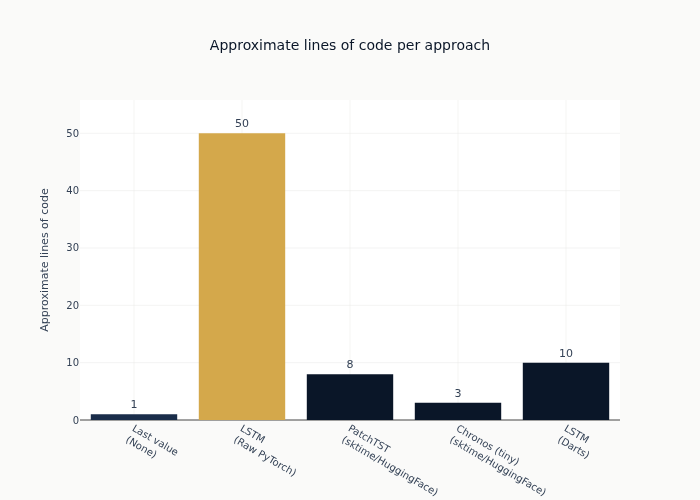

In [16]:
if results:
    _labels = [f"{r['Model']}<br>({r['Library']})" for r in results]
    _lines = [int(str(r["Lines"]).lstrip("~")) for r in results]
    _colors = [
        COLORS["slate"]
        if r["Library"] == "None"
        else COLORS["amber"]
        if "PyTorch" in r["Library"]
        else COLORS["blue"]
        for r in results
    ]
    fig = go.Figure(
        go.Bar(x=_labels, y=_lines, marker_color=_colors, text=_lines, textposition="outside")
    )
    fig.update_layout(
        title="Approximate lines of code per approach",
        yaxis_title="Approximate lines of code",
        showlegend=False,
    )
    show_plotly_with_alt(
        fig,
        "A bar chart of approximate lines of code, one bar per approach, labelled with "
        "the model and the library. The raw PyTorch bar is amber, the library-wrapped "
        "bars navy, and the no-library baseline slate.",
    )

## 何时使用各方法

本节正文（第 13.7 节）比较的是库的*能力*（面板支持、基础模型）。这张表关注的是*实现体验*：

| 方法 | 实现工作量 | 灵活性 | 最适合 |
|----------|----------------------|-------------|----------|
| **Raw PyTorch** | 约 50 行，完整样板代码 | 完全掌控一切 | 自定义架构、横截面排序、研究 |
| **sktime** | 约 3-8 行 | 受限于 `fit`/`predict` API | 快速原型、后端切换、标准化基准测试 |
| **Darts** | 约 10 行 | 中等（自带 `TimeSeries` 容器） | 概率预测、自包含生态 |
| **Chronos / TSFMs** | 约 3 行，零训练 | 无（仅零样本） | 即时基线、冷启动场景 |

sktime 不是模型库。它是一个单一接口——`fit`、`predict`、`update`——委托给 NeuralForecast（LSTM、TCN）、PyTorch Forecasting（N-BEATS、TFT）、HuggingFace（PatchTST、Chronos）和经典方法（ETS、ARIMA），因此无需改动数据管道，就能对 LSTM、基础模型和 ARIMA 做基准测试。这个 notebook 还展示了这种间接层的代价：这里有两个后端无法安装或调用，而接口对不存在的后端无能为力。

In [17]:
if results:
    _libraries = [r for r in results if r["Library"] != "None"]
    print(f"Library approaches that ran: {len(_libraries)} of 6 attempted")
    trainable = [r for r in _libraries if r["Trainable"]]
    zero_shot = [r for r in _libraries if not r["Trainable"]]
    if trainable:
        fastest = min(trainable, key=lambda r: r["Fit + Predict (s)"])
        print(
            f"Fastest to fit and predict: {fastest['Model']} ({fastest['Library']}) "
            f"at {fastest['Fit + Predict (s)']}s"
        )
    if zero_shot:
        print(f"Zero-shot models: {len(zero_shot)} (no training required)")

Library approaches that ran: 4 of 6 attempted
Fastest to fit and predict: LSTM (Darts) at 8.3s
Zero-shot models: 1 (no training required)


## 关键要点

1. **表中有两列可以跨行比较，而误差列不能。** 代码行数是其中之一；另一列是实际耗时（wall-clock time），它对每一行都按相同跨度计量——训练和预测合计——因为这是所有方法唯一共有的边界。Chronos 完全不做训练，因此把二者拆开会让它的单元格为空，并使该列无法阅读。误差则是无法比较的那一列：原生 PyTorch 行是在长滚动测试集上评分的归一化目标，sktime 和 Darts 行是在单次 `HORIZON` 步预测上评分的原始价格水平。量纲差距会让数值移动数个数量级，样本差距会改变其方差。表中列出 `Target Scale` 和 `Evaluation Points`，就是为了让这种不匹配不会被忽略。
2. **最后值基线是最该先读的一行。** 它与原生 PyTorch 行共享量纲和测试点，因此这两者真正可比——而且它无需训练。在价格水平上，要击败它并非易事。
3. **价格水平上的秩相关不是预测能力的度量。** 任何跟踪价格水平的预测都会得到接近 1 的分数，包括基线。这就是为什么这个 notebook 的 `ic` 列只是诊断指标，而多资产 notebook 改为计算*横截面* IC，它提出的问题是价格水平本身无法替你回答的。
4. **sktime 是接口，不是模型库。** 一个 `fit`/`predict` 表面委托给 NeuralForecast、PyTorch Forecasting、HuggingFace 和经典方法，正是这一点让 LSTM、Chronos 和 ARIMA 无需改动数据管道即可进行基准测试。Darts 做了相反的取舍：自带容器和自带模型，自包含而非委托。
5. **封装器的代价在于它没有暴露的东西。** 自定义损失、非标准训练调度或横截面目标，正是 `fit`/`predict` 表面不再有用的地方，而这也是本章其余部分用原生 PyTorch 来写的原因。
6. **可安装性也是比较的一部分。** 并非每个封装器都运行了：打印出的计数说明在本环境中有多少个尝试的演示完成了，上面的各节则说明每个被什么挡住了。

**下一步**：`12_case_study_insights` 不再局限于单序列演示，而是在 walk-forward validation（滚动前向验证）下汇总这些架构在本书案例研究中的表现。